# Figure 5: Sprox-seq human tonsil, RNA and protein, with protein complexes held out

Section B1 of the Sprox-seq human tonsil data (Wang, Xia et al., Cell 2026; GEO GSE304749): 3,204 Visium spots in tissue,
38,606 genes, 46 antibody probes and 1,692 proximity ligation (PLA) products. Saturn is fitted on RNA and on the protein
abundance summed from the PLA products. The products themselves never enter the loss, so they are tested afterwards as
held-out features along each axis.

The figure shows the assay (a, a schematic), the marker compartments (b), both isodepths and their domains (c), programme scores
and protein values along the axes (d), fitted feature functions (e), the specificity of held-out complexes along each axis (f, g)
and example cell-cell contact complexes as fitted functions (h). The fit quality and the share of changing complexes are shown
as supporting plots without a panel letter.

**Conda env:** `spatialmultivelo`. **Device:** CPU. **Run time:** about 15 to 30 min (the fit and 2 x 200 rotations).

Fig. 5a is a schematic of the Sprox-seq assay; it is not drawn here.

## Setup
The published fit ran with 4 torch threads and `OMP_NUM_THREADS` unset. A CPU fit depends on the thread count, so the thread
variables are removed before numpy and torch are imported, and `threads=4` is passed to the fit.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.pop(v, None)
import re
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.io import mmread
from scipy.spatial import cKDTree
from scipy.stats import rankdata
from threadpoolctl import threadpool_limits

import saturn
from saturn import crossterm as CT, piecewise as pw
from saturn.theme import MODALITY, ANCHOR, CMAP, REFERENCE

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig5"; OUT.mkdir(parents=True, exist_ok=True)
saturn.theme.set_theme(7)

INK = ANCHOR["ink"]
def cbar(fig, ax, sc_, label, ticks=None):
    """colour bar right of a map, label on top so it never meets the next panel"""
    cb = fig.colorbar(sc_, cax=ax.inset_axes([1.03, 0.05, 0.05, 0.72]), ticks=ticks)
    cb.ax.tick_params(labelsize=5.5); cb.ax.set_title(label, fontsize=5.5, pad=2, loc="left")
    return cb

RHO = {"RNA": r"$\rho_{\mathrm{RNA}}$", "Protein": r"$\rho_{\mathrm{Protein}}$"}

## Data
The Visium RNA triplet, the spot positions and the PLA count matrix of section B1. Spots in tissue and present in both layers
are kept. Coordinates are `(col, -row)` in full-resolution pixels.

In [2]:
GSM = WORK / "GSM9156294_B1"
barcodes = pd.read_csv(f"{GSM}_barcodes.tsv.gz", header=None)[0].astype(str).values
gene_names = pd.read_csv(f"{GSM}_features.tsv.gz", sep="\t", header=None)[1].astype(str).values
X_all = sp.csr_matrix(mmread(f"{GSM}_matrix.mtx.gz").T)
pos = pd.read_csv(f"{GSM}_tissue_positions.csv.gz", index_col=0)
pla = pd.read_csv(WORK / "GSM9156303_B1-PLA_count_matrix.txt.gz", sep="\t", index_col=0)   # products x spots

in_tissue = set(pos.index[pos.in_tissue == 1]) & set(pla.columns)
bc = [b for b in barcodes if b in in_tissue]
X = X_all[pd.Index(barcodes).get_indexer(bc)]
pla = pla[bc]
coords = np.c_[pos.loc[bc, "pxl_col_in_fullres"].values.astype(float), -pos.loc[bc, "pxl_row_in_fullres"].values.astype(float)]
coords_z = saturn.zscore_coords(coords)
print("spots", len(bc), " genes", X.shape[1], " PLA products", pla.shape[0])

spots 3204  genes 38606  PLA products 1692


## Targets
A PLA product is named `<probeA>:<probeB>`. The abundance of a probe is the sum of all products that contain it, in either
position. These 46 probe marginals (isotype controls included) go through `protein_clr_pca`: CLR per spot, then 10 PCs.

In [3]:
tokens = np.array([p.split(":") for p in pla.index])
probes = sorted(set(tokens.ravel()))
C = pla.values.T.astype(float)                                                       # spots x products
M = np.column_stack([C[:, tokens[:, 0] == p].sum(1) + C[:, tokens[:, 1] == p].sum(1) for p in probes])
Y_P_raw, info_P = saturn.protein_clr_pca(sp.csr_matrix(M), K=10)
depth_P = info_P["depth"]
print(len(probes), "probes; median PLA reads per spot", np.median(C.sum(1)))

46 probes; median PLA reads per spot 5413.5


The RNA target is Poisson GLM-PCA (`saturn.rna_glmpc_real`, 10 factors on 3,000 genes). GLM-PCA starts from an unseeded random
draw, so the saved RNA target of the published fit is read from `published/targets_sproxseq_B1_p46.npz` (key `Y_RNA`, before
depth regression). Its depth offset is the UMI count over genes detected in at least 1% of spots, as in `rna_glmpc_real`.

In [4]:
Y_R_raw = np.load(PUB / "targets_sproxseq_B1_p46.npz", allow_pickle=True)["Y_RNA"]
det = np.asarray((X > 0).mean(0)).ravel() >= 0.01
depth_R = np.asarray(X[:, det].sum(1)).ravel().astype(float)

Each modality's own log depth is regressed out of its factors, which are then rescaled with `scale_target`.

In [5]:
def regress_depth(Y, depth):
    ld = np.log1p(np.asarray(depth, float)); A = np.c_[np.ones_like(ld), ld]
    Y = np.asarray(Y, float); Y = Y - A @ np.linalg.lstsq(A, Y, rcond=None)[0]
    return saturn.scale_target(Y, "global")

Y_R, Y_P = regress_depth(Y_R_raw, depth_R), regress_depth(Y_P_raw, depth_P)
targets, modalities = [Y_R, Y_P], ["RNA", "Protein"]
print("RNA    ", saturn.check_target(Y_R, depth=depth_R, coords=coords))
print("Protein", saturn.check_target(Y_P, depth=depth_P, coords=coords))

RNA     {'var_share': [0.2863, 0.2786, 0.1622, 0.0569, 0.0504, 0.0424, 0.0394, 0.0339, 0.0265, 0.0235], 'elbow': None, 'depth_corr': [0.115, 0.019, 0.058, 0.029, 0.036], 'depth_leak': 0.115, 'moran': 0.822}
Protein {'var_share': [0.3315, 0.1618, 0.1248, 0.1276, 0.0768, 0.0505, 0.0433, 0.0326, 0.027, 0.0242], 'elbow': None, 'depth_corr': [0.135, 0.16, 0.003, 0.137, 0.039], 'depth_leak': 0.16, 'moran': 0.741}


## Saturn fit
Seed 42, CPU, 4 threads, a final refit on all spots for 3,000 epochs, no masks, no tail penalty. A rerun reuses the saved weights.

In [6]:
FIT = OUT / "fit"
if not (FIT / "saturn_best.pt").exists():
    res = saturn.fit(targets, coords_z, modalities, seeds=[42], masks=[None, None], refit_all_epochs=3000, device="cpu",
                     threads=4, lam_tail=0.0, depth=dict(RNA=depth_R, Protein=depth_P))
    res.save(str(FIT), coords=coords, barcodes=bc)
model = saturn.load_model(str(FIT / "saturn_best.pt"), [Y_R.shape[1], Y_P.shape[1]])
axes_raw = saturn.decompose(model, coords_z)[0].astype(float)
R2 = saturn.r2_split(model, coords_z, targets, None, modalities)
print(pd.DataFrame(R2).round(3))

                   RNA  Protein
full             0.611    0.557
own_axis_only    0.442    0.428
other_axes_only  0.278    0.238


## Fit quality
Not a lettered panel of Fig. 5. Variance explained for each target with the full model, the own axis only (cross term frozen at its mean) and the cross axis only.

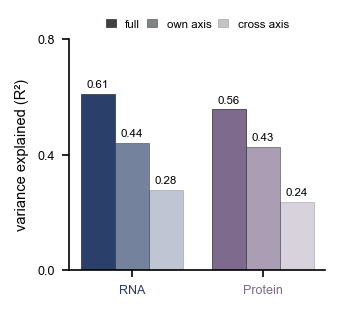

In [7]:
fig, ax = plt.subplots(figsize=(2.2, 2.0))
x, w = np.arange(2), 0.26
for i, (key, alpha, lbl) in enumerate([("full", 1.0, "full"), ("own_axis_only", 0.65, "own axis"), ("other_axes_only", 0.3, "cross axis")]):
    v = [R2[m][key] for m in modalities]
    ax.bar(x + (i - 1) * w, v, w, color=[MODALITY[m] for m in modalities], alpha=alpha, edgecolor=INK, lw=0.4)
    for xx, vv in zip(x + (i - 1) * w, v):
        ax.text(xx, vv + 0.015, f"{vv:.2f}", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks(x); ax.set_xticklabels(modalities)
for tl, m in zip(ax.get_xticklabels(), modalities): tl.set_color(MODALITY[m])
ax.set_ylim(0, 0.8); ax.set_yticks([0, 0.4, 0.8]); ax.set_ylabel("variance explained (R²)")
ax.legend(handles=[Patch(fc=INK, alpha=a_, ec=INK, lw=0.4, label=l_) for a_, l_ in [(1, "full"), (0.65, "own axis"), (0.3, "cross axis")]],
          fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=0.9, columnspacing=0.6)
plt.show()

## Compartments from marker genes
Compartments come from the authors' marker lists on log-normalised RNA. A spot is B follicle if its B score is above 0.3, and then
takes its best zone (dark zone DZ, light zone LZ, naive follicle NBC). Remaining spots with a T score above 0.3 are T zone, the rest
extrafollicular (EF). Spots with a keratin score above 1.5 are crypt epithelium.

In [8]:
rna = ad.AnnData(X.astype(np.float64), obs=pd.DataFrame(index=bc), var=pd.DataFrame(index=gene_names))
rna.var_names_make_unique()
total = np.asarray(X.sum(1)).ravel().astype(float)
mito = np.asarray(X[:, rna.var_names.str.startswith("MT-")].sum(1)).ravel() / total.clip(1)
sc.pp.normalize_total(rna, target_sum=1e4); sc.pp.log1p(rna)

def module_z(genes):
    v = np.asarray(rna[:, [g for g in genes if g in rna.var_names]].X.todense()).mean(1).ravel()
    return (v - v.mean()) / v.std()

S = pd.DataFrame({k: module_z(g) for k, g in dict(DZ=["CXCR4", "AICDA", "MME", "FOXP1"], LZ=["CD83", "LMO2", "BCL2A1"],
                                                  NBC=["IGHD", "FCER2", "TCL1A"], B=["MS4A1", "CD19", "CD79A"],
                                                  T=["CD3E", "CD3D", "CD2"]).items()}, index=bc)
zone = np.where(S.B > 0.3, S[["DZ", "LZ", "NBC"]].idxmax(1), "other")
zone = np.where((zone == "other") & (S["T"] > 0.3), "T", zone)
zone = np.where(zone == "other", "EF", zone)
epithelium = module_z(["KRT5", "KRT13", "KRT4", "KRT14", "SPRR3"]) > 1.5
compartment = np.where(epithelium, "epithelium", zone)

## Fig. 5b: compartments assigned from marker-gene scores
n = 3,204 spots; the number of spots per compartment is in the key.

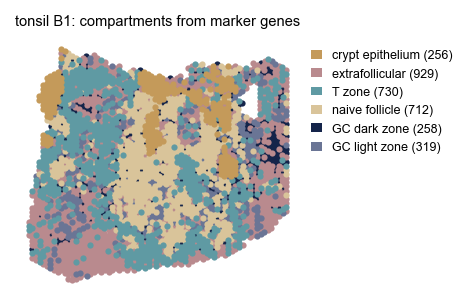

In [9]:
COMP = {"epithelium": ANCHOR["ochre"], "EF": ANCHOR["rose"], "T": ANCHOR["teal"], "NBC": ANCHOR["sand"],
        "DZ": ANCHOR["night"], "LZ": ANCHOR["slate"]}
COMP_NAME = {"epithelium": "crypt epithelium", "EF": "extrafollicular", "T": "T zone", "NBC": "naive follicle",
             "DZ": "GC dark zone", "LZ": "GC light zone"}
fig, ax = plt.subplots(figsize=(3.6, 2.2))
saturn.plotting.spatial(ax, coords, compartment, "tonsil B1: compartments from marker genes", discrete=True, colors=COMP)
ax.legend(handles=[Patch(fc=COMP[k], label=f"{COMP_NAME[k]} ({int((compartment == k).sum())})") for k in COMP],
          loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=0.9)
plt.show()

## Orienting the axes
The sign of an isodepth is arbitrary. `rho_RNA` is oriented to increase with the distance to the crypt epithelium, `rho_Protein`
from the T zone to the naive follicle.

In [10]:
dist_epi = cKDTree(coords[epithelium]).query(coords)[0]
t_to_b = np.select([zone == "T", zone == "NBC"], [-1.0, 1.0], 0.0)
axes = saturn.orient(axes_raw, np.c_[dist_epi, t_to_b])
d = {"RNA": axes[:, 0], "Protein": axes[:, 1]}

## Domains along each axis
Each modality is segmented on its own axis with its own target: `choose_k` takes the elbow of GASTON's DP error curve and
`gaston_domains` assigns the spots (domain 0 = low end). The labels come from the marker genes and proteins of each domain
(`saturn.annotate`, below).

In [11]:
def domains_on(dd, Y):
    k, _ = saturn.domains.choose_k(dd, np.asarray(Y, float))
    lab = saturn.domains.gaston_domains(dd, np.asarray(Y, float), n_domains=k)
    order = np.argsort([np.median(dd[lab == i]) for i in range(lab.max() + 1)])
    return np.argsort(order)[lab]

lab = {"RNA": domains_on(d["RNA"], Y_R), "Protein": domains_on(d["Protein"], Y_P)}
NAMES = {"RNA": {0: "crypt epithelium", 1: "subepithelial IgA plasma", 2: "mantle & T zone", 3: "germinal centre"},
         "Protein": {0: "T / Tfh-FDC", 1: "naive mantle B", 2: "CD9+ CD38+ surface"}}
DOMCOL = {"crypt epithelium": ANCHOR["ochre"], "subepithelial IgA plasma": ANCHOR["plum"], "mantle & T zone": ANCHOR["sage"],
          "germinal centre": ANCHOR["night"], "T / Tfh-FDC": ANCHOR["teal"], "naive mantle B": ANCHOR["sand"],
          "CD9+ CD38+ surface": ANCHOR["rust"]}
dcol = {m: [DOMCOL[NAMES[m][k]] for k in range(len(NAMES[m]))] for m in modalities}
for m in modalities:
    print(m, "K", lab[m].max() + 1, np.bincount(lab[m]).tolist())

RNA K 4 [390, 522, 1536, 756]
Protein K 3 [1075, 1012, 1117]


Domain tables: size, position along the axis, top markers and compartment composition. RNA counts use `annotate_counts`, protein
CLR values per target protein (A and B probes summed, isotype controls not used as features) use `annotate_continuous`.

In [12]:
targets_prot = sorted({p.split("_")[0] for p in probes})
P_counts = np.column_stack([M[:, [p.split("_")[0] == t for p in probes]].sum(1) for t in targets_prot])
L = np.log1p(P_counts); clr = L - L.mean(1, keepdims=True)
keep = [i for i, t in enumerate(targets_prot) if "IgG" not in t]
pd.set_option("display.max_colwidth", None)
tab_R = saturn.annotate.annotate_counts(X, gene_names, lab["RNA"], d["RNA"], "RNA", depth=depth_R,
                                        cats=dict(compartment=compartment), labels=NAMES["RNA"])
tab_P = saturn.annotate.annotate_continuous(clr[:, keep], np.array(targets_prot)[keep], lab["Protein"], d["Protein"], "Protein",
                                            depth=depth_P, cats=dict(compartment=compartment), labels=NAMES["Protein"])
display(tab_R); display(tab_P)

,modality,domain,label,n_spots,isodepth,median_depth,compartment,gradient_feats,markers
0,RNA,0,crypt epithelium,390,"[-2.47, -0.55]",14297.0,"{""DZ"": 0.05, ""EF"": 0.13, ""LZ"": 0.03, ""NBC"": 0.17, ""T"": 0.33, ""epithelium"": 0.29}",386,MT-CO3(+0.7); S100A8(+4.0); MT-CO2(+0.6); MT-CO1(+0.6); MIR205HG(+2.5); MT-ND4(+0.7); MT-ATP6(+0.6); TACSTD2(+3.4)
1,RNA,1,subepithelial IgA plasma,522,"[-0.55, -0.03]",10081.0,"{""DZ"": 0.08, ""EF"": 0.27, ""LZ"": 0.08, ""NBC"": 0.21, ""T"": 0.12, ""epithelium"": 0.24}",395,IGKC(+1.1); IGHG3(+1.6); MIR205HG(+2.7); IGHG1(+1.0); IGLC3(+1.0); IGLC2(+0.9); IGHA1(+1.6); LTF(+2.7)
2,RNA,2,mantle & T zone,1536,"[-0.03, 0.41]",16602.5,"{""DZ"": 0.07, ""EF"": 0.19, ""LZ"": 0.1, ""NBC"": 0.34, ""T"": 0.29, ""epithelium"": 0.01}",410,IGHM(+0.9); LINC00926(+1.1); FCMR(+1.0); CXCL13(+0.7); TXNIP(+0.7); IFITM1(+0.9); BANK1(+1.0); TRIM22(+0.8)
3,RNA,3,germinal centre,756,"[0.41, 1.88]",18053.5,"{""DZ"": 0.12, ""EF"": 0.59, ""LZ"": 0.15, ""NBC"": 0.02, ""T"": 0.13, ""epithelium"": 0.0}",460,IRAG2(+1.4); CR2(+0.9); RGS13(+1.9); HMGB2(+1.3); PLCG2(+1.0); HMCES(+1.8); IGHG1(+0.7); SERPINA9(+2.3)


,modality,domain,label,n_spots,isodepth,median_depth,compartment,gradient_feats,markers
0,Protein,0,T / Tfh-FDC,1075,"[-6.95, -0.50]",13704.0,"{""DZ"": 0.06, ""EF"": 0.4, ""LZ"": 0.1, ""NBC"": 0.08, ""T"": 0.31, ""epithelium"": 0.06}",27,"IgD (-0.51, t-42); CD20 (-0.37, t-38); CD32 (-0.43, t-38); CD19 (-0.24, t-37); PDL2 (+0.16, t+31); CD86 (+0.14, t+27); CD28 (+0.20, t+26); CD279 (+0.24, t+26)"
1,Protein,1,naive mantle B,1012,"[-0.50, 0.37]",10346.0,"{""DZ"": 0.05, ""EF"": 0.16, ""LZ"": 0.08, ""NBC"": 0.43, ""T"": 0.26, ""epithelium"": 0.01}",28,"IgD (+0.58, t+44); ICAM1 (-0.25, t-35); CD19 (+0.21, t+30); CD9 (-0.36, t-30); VCAM1 (-0.25, t-29); CD20 (+0.27, t+28); ITGA4 (+0.11, t+25); CD32 (+0.25, t+24)"
2,Protein,2,CD9+ CD38+ surface,1117,"[0.38, 1.76]",8756.0,"{""DZ"": 0.13, ""EF"": 0.3, ""LZ"": 0.12, ""NBC"": 0.17, ""T"": 0.12, ""epithelium"": 0.16}",28,"CD9 (+0.48, t+31); CD279 (-0.33, t-31); CD38 (+0.19, t+24); CD147 (+0.18, t+23); CD3 (-0.26, t-21); CD4 (-0.13, t-16); CD28 (-0.15, t-16); ICAM1 (+0.14, t+15)"


## Fig. 5c: rho_RNA, RNA domains, rho_Protein and protein domains
`rho_RNA` runs from the crypt epithelium into the lymphoid interior, `rho_Protein` from the T zone to the B follicle. The number of
spots per domain is in the key.

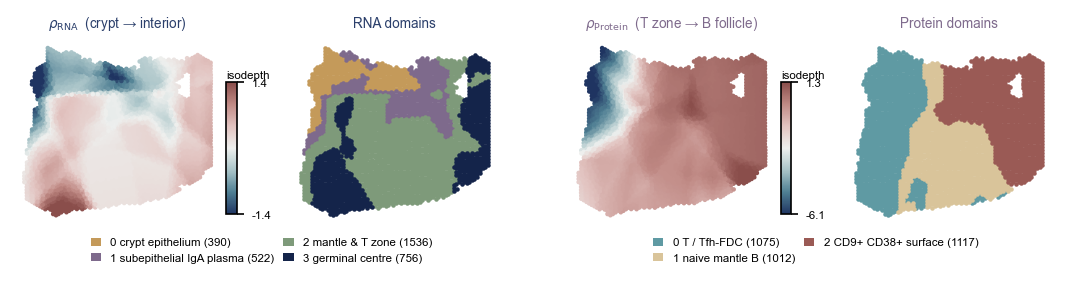

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(7.2, 2.6), gridspec_kw=dict(wspace=0.35))
fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.25)
for j, m in enumerate(modalities):
    lo, hi = np.percentile(d[m], [1, 99])
    s_ = saturn.plotting.spatial(ax[2 * j], coords, d[m], "", cmap=CMAP["score"], vmin=lo, vmax=hi)
    cbar(fig, ax[2 * j], s_, "isodepth", ticks=[lo, hi]).ax.set_yticklabels([f"{lo:.1f}", f"{hi:.1f}"])
    ax[2 * j].set_title(f"{RHO[m]}  ({'crypt → interior' if m == 'RNA' else 'T zone → B follicle'})", color=MODALITY[m], fontsize=6.5)
    saturn.plotting.spatial(ax[2 * j + 1], coords, lab[m], "", discrete=True, colors=dcol[m])
    ax[2 * j + 1].set_title(f"{m} domains", color=MODALITY[m], fontsize=6.5)
    ax[2 * j + 1].legend(handles=[Patch(fc=dcol[m][k], label=f"{k} {NAMES[m][k]} ({int((lab[m] == k).sum())})") for k in NAMES[m]],
                         loc="upper center", bbox_to_anchor=(-0.15, -0.02), ncol=2, fontsize=5.5, handlelength=0.9, columnspacing=0.8)
plt.show()

## Fig. 5d: programme scores along rho_RNA and protein values along rho_Protein
Top: pre-declared tonsil programmes. Each gene's log-normalised expression is rank-transformed, log UMI depth and mitochondrial share
are regressed out of the ranks, and the gene residuals are averaged per programme, z-scored and averaged per octile of `rho_RNA`.
Bottom: protein counts per target (A and B probes summed), normalised to 10,000 per spot, log-transformed, z-scored and averaged per
octile of `rho_Protein`.

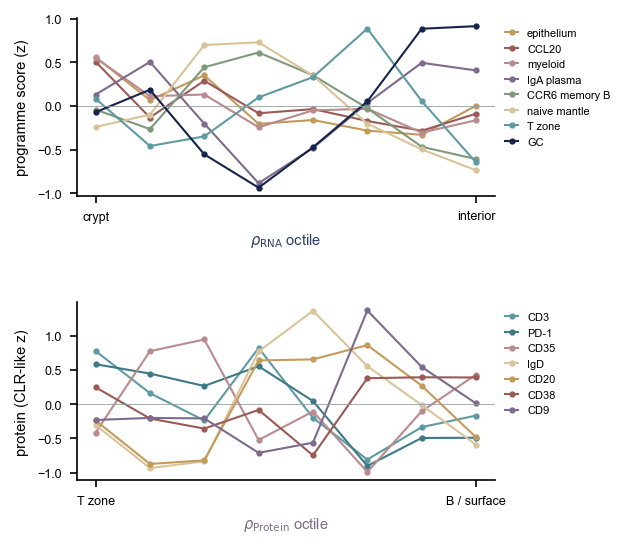

In [14]:
def resid(Mx, covs):
    Ac = np.column_stack([np.ones(len(covs[0]))] + [rankdata(c) for c in covs])
    Rk = np.apply_along_axis(rankdata, 0, Mx)
    Rk = Rk - Ac @ np.linalg.lstsq(Ac, Rk, rcond=None)[0]
    return (Rk - Rk.mean(0)) / Rk.std(0).clip(1e-9)

def octiles(t, nb=8):
    return np.minimum((np.argsort(np.argsort(t)) * nb) // len(t), nb - 1)

RNA_PROG = {"epithelium": (["KRT5", "KRT13", "KRT4", "KRT14", "SPRR3"], ANCHOR["ochre"]), "CCL20": (["CCL20"], ANCHOR["rust"]),
            "myeloid": (["S100A8", "S100A9", "LYZ"], ANCHOR["rose"]), "IgA plasma": (["IGHA1", "JCHAIN", "MZB1", "XBP1"], ANCHOR["plum"]),
            "CCR6 memory B": (["CCR6"], ANCHOR["sage"]), "naive mantle": (["IGHD", "FCER2", "TCL1A", "SELL"], ANCHOR["sand"]),
            "T zone": (["CCL19", "CCL21", "CCR7", "CD3E"], ANCHOR["teal"]),
            "GC": (["BCL6", "RGS13", "SERPINA9", "MEF2B", "AICDA", "MKI67"], ANCHOR["night"])}
PROT_MK = [("CD3", "CD3", ANCHOR["teal"]), ("CD279", "PD-1", ANCHOR["sea"]), ("CD35", "CD35", ANCHOR["rose"]),
           ("IgD", "IgD", ANCHOR["sand"]), ("CD20", "CD20", ANCHOR["ochre"]), ("CD38", "CD38", ANCHOR["rust"]), ("CD9", "CD9", ANCHOR["plum"])]
Pdf = pd.DataFrame(P_counts, columns=targets_prot, index=bc)
Lp = np.log1p(Pdf.div(Pdf.sum(1), axis=0) * 1e4); Zp = (Lp - Lp.mean()) / Lp.std()

fig, ax = plt.subplots(2, 1, figsize=(3.6, 4.0), gridspec_kw=dict(hspace=0.6))
b8 = octiles(d["RNA"])
for k, (genes, col) in RNA_PROG.items():
    v_ = resid(np.asarray(rna[:, [g for g in genes if g in rna.var_names]].X.todense()), [np.log1p(total), mito]).mean(1)
    v_ = (v_ - v_.mean()) / v_.std()
    ax[0].plot(range(8), [v_[b8 == i].mean() for i in range(8)], "-o", color=col, ms=2, lw=1.0, label=k)
ax[0].set_xticks([0, 7]); ax[0].set_xticklabels(["crypt", "interior"])
ax[0].set_xlabel(f"{RHO['RNA']} octile", color=MODALITY["RNA"]); ax[0].set_ylabel("programme score (z)")
b8 = octiles(d["Protein"])
for t, nm, col in PROT_MK:
    ax[1].plot(range(8), [Zp[t].values[b8 == i].mean() for i in range(8)], "-o", color=col, ms=2, lw=1.0, label=nm)
ax[1].set_xticks([0, 7]); ax[1].set_xticklabels(["T zone", "B / surface"])
ax[1].set_xlabel(f"{RHO['Protein']} octile", color=MODALITY["Protein"]); ax[1].set_ylabel("protein (CLR-like z)")
for a_ in ax:
    a_.axhline(0, color=REFERENCE, lw=0.4); a_.legend(fontsize=5.3, loc="upper left", bbox_to_anchor=(1.0, 1.0), handlelength=1.2)
plt.show()

## Fig. 5e: CXCL13 and BCL6 along rho_RNA, LFA-1 and CD19 protein along rho_Protein
Each feature (proteins with A and B probes summed) is fitted per domain with GASTON's Poisson
model (library size as offset, likelihood-ratio gate t = 0.1). Columns: the original map (log CP10k), the fitted function at every
spot, and the means of 25 equal-width bins with the fitted function. R² is computed on the rate in those bins.

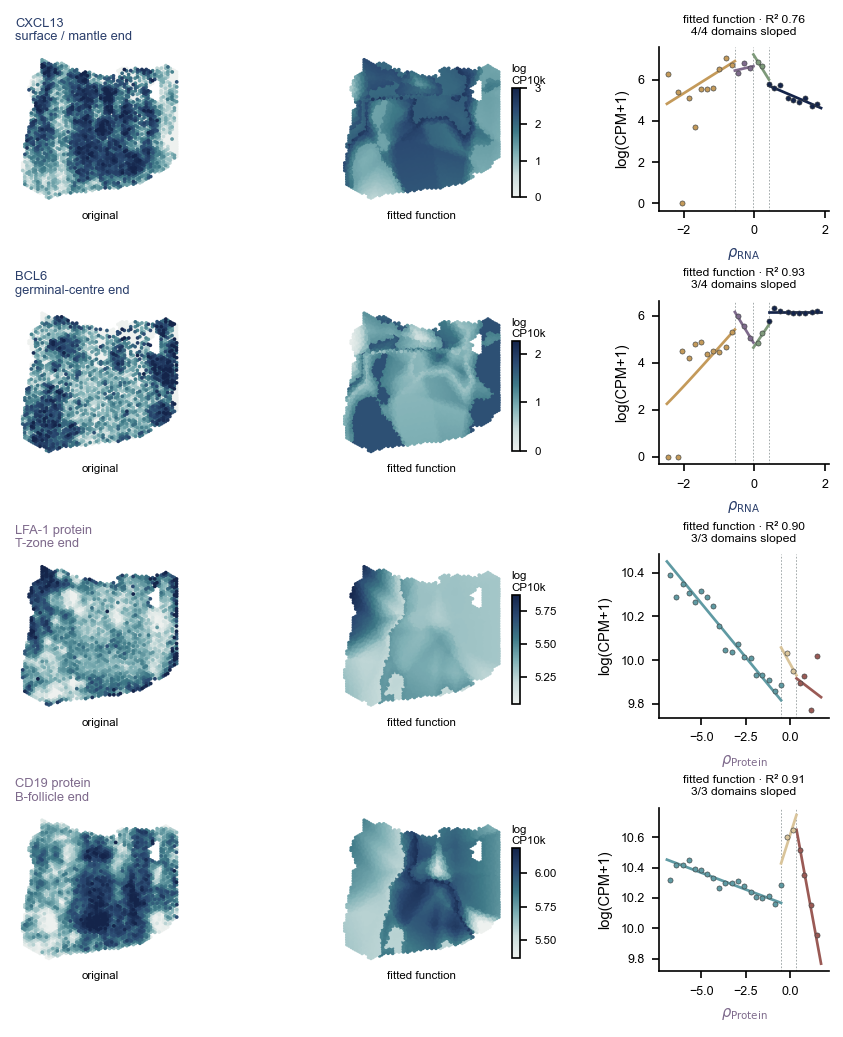

In [15]:
X_csc = X.tocsc().astype(float)
counts = {"RNA": X_csc, "Protein": P_counts}
feat_names = {"RNA": gene_names, "Protein": np.array(targets_prot)}
lib = {"RNA": total.clip(1), "Protein": P_counts.sum(1).clip(1)}

def feature_function(m, feat, n_bins=25):
    j = int(np.where(feat_names[m] == feat)[0][0]); Xm = counts[m]
    c = np.asarray(Xm[:, j].todense()).ravel() if sp.issparse(Xm) else Xm[:, j]
    lb_, dd, ll = lib[m], d[m], lab[m]
    sl, it = (v_[0] for v_ in pw.fit_poisson(c[:, None], lb_, ll, dd, t=0.1))
    bi, _, kp = saturn.domains.isodepth_bins(dd, n_bins)
    db = np.array([dd[bi == b].mean() for b in kp])
    y = np.array([c[bi == b].sum() for b in kp]) / np.maximum(np.array([lb_[bi == b].sum() for b in kp]), 1)
    bl = np.array([np.bincount(ll[bi == b], minlength=ll.max() + 1).argmax() for b in kp])
    pr = np.exp(it[bl] + sl[bl] * db)
    r2 = 1 - ((y - pr) ** 2).sum() / max(((y - y.mean()) ** 2).sum(), 1e-12)
    return dict(raw=np.log1p(c / lb_ * 1e4), spot=np.log1p(np.exp(it[ll] + sl[ll] * dd) * 1e4), sl=sl, it=it,
                bx=db, by=np.log1p(y * 1e6), bl=bl, r2=r2, n_sloped=int((np.abs(sl) > 1e-9).sum()))

def along(ax, m, bx, by, bl, curve, ylabel):
    """bin means coloured by domain, the fitted function per domain, dotted domain boundaries"""
    for k in range(lab[m].max() + 1):
        q = bl == k
        ax.scatter(bx[q], by[q], s=6, color=dcol[m][k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.linspace(d[m][lab[m] == k].min(), d[m][lab[m] == k].max(), 20)
        ax.plot(xs, curve(k, xs), color=dcol[m][k], lw=1.3, zorder=2)
    for b in saturn.domains.boundaries(d[m], lab[m]):
        ax.axvline(b, color=REFERENCE, lw=0.4, ls=(0, (2, 2)), zorder=1)
    ax.set_xlabel(RHO[m], color=MODALITY[m]); ax.set_ylabel(ylabel)

FEATS = [("RNA", "CXCL13", "CXCL13", "surface / mantle end"), ("RNA", "BCL6", "BCL6", "germinal-centre end"),
         ("Protein", "LFA1", "LFA-1 protein", "T-zone end"), ("Protein", "CD19", "CD19 protein", "B-follicle end")]
fig, ax = plt.subplots(len(FEATS), 3, figsize=(7.0, 2.0 * len(FEATS)), gridspec_kw=dict(wspace=0.9, hspace=0.55))
for r, (m, feat, title, sub) in enumerate(FEATS):
    F = feature_function(m, feat)
    lo, hi = np.percentile(np.r_[F["raw"], F["spot"]], [2, 99]); o = np.argsort(F["raw"])
    saturn.plotting.spatial(ax[r, 0], coords[o], F["raw"][o], "", cmap=CMAP["expression"], vmin=lo, vmax=hi)
    s_ = saturn.plotting.spatial(ax[r, 1], coords, F["spot"], "", cmap=CMAP["expression"], vmin=lo, vmax=hi)
    cbar(fig, ax[r, 1], s_, "log\nCP10k")
    ax[r, 0].set_title(f"{title}\n{sub}", color=MODALITY[m], loc="left", fontsize=6.2)
    ax[r, 0].text(0.5, -0.04, "original", transform=ax[r, 0].transAxes, ha="center", va="top", fontsize=5.5)
    ax[r, 1].text(0.5, -0.04, "fitted function", transform=ax[r, 1].transAxes, ha="center", va="top", fontsize=5.5)
    along(ax[r, 2], m, F["bx"], F["by"], F["bl"], lambda k, xs, F=F: np.log1p(np.exp(F["it"][k] + F["sl"][k] * xs) * 1e6), "log(CPM+1)")
    ax[r, 2].set_title(f"fitted function · R² {F['r2']:.2f}\n{F['n_sloped']}/{len(F['sl'])} domains sloped", fontsize=5.8)
plt.show()

## Held-out complexes along each axis
The statistic is isotype-corrected specificity. For a complex `a:b` in a set of spots it is the pooled `log2((O+1)/(E+1))` minus the
same quantity for the mouse-IgG isotype products of each partner, averaged over the two partners. `O` is the PLA reads and `E` the
per-spot independence expectation `row_a * col_b / total`. Probe suffixes are dropped, control products excluded, and complexes
need at least 2,000 reads.

In [16]:
strip = lambda t: re.sub(r"_[AB]$", "", t)
A, B = np.array([strip(t) for t in tokens[:, 0]]), np.array([strip(t) for t in tokens[:, 1]])
ISO, CTRL, MIN_READS = ["mIgG1", "mIgG2a", "mIgG2b"], ["mIgG1", "mIgG2a", "mIgG2b", "HIgG"], 2000

rows_t = {t: C[:, A == t].sum(1) for t in set(A)}; cols_t = {t: C[:, B == t].sum(1) for t in set(B)}
tot = C.sum(1).clip(1)
pairs = sorted({(a, b) for a, b in zip(A, B) if a not in CTRL and b not in CTRL})
O = np.column_stack([C[:, (A == a) & (B == b)].sum(1) for a, b in pairs])
E = np.column_stack([rows_t[a] * cols_t[b] / tot for a, b in pairs])
tg = sorted({x for p in pairs for x in p})
IO, IE = [], []
for x in tg:
    ps = {(a, b) for a, b in zip(A, B) if (a == x and b in ISO) or (b == x and a in ISO)}
    IO.append(sum(C[:, (A == a) & (B == b)].sum(1) for a, b in ps)); IE.append(sum(rows_t[a] * cols_t[b] / tot for a, b in ps))
IO, IE = np.column_stack(IO), np.column_stack(IE)
ok = O.sum(0) >= MIN_READS
pairs, O, E = [p for p, k in zip(pairs, ok) if k], O[:, ok], E[:, ok]
names_cx = [f"{a}:{b}" for a, b in pairs]
ia, ib = np.array([tg.index(a) for a, _ in pairs]), np.array([tg.index(b) for _, b in pairs])

def specificity(H, O=O, E=E, ia=ia, ib=ib):
    """H: spots x groups (0/1). Returns groups x complexes."""
    lo = np.log2((H.T @ O + 1) / (H.T @ E + 1)); li = np.log2((H.T @ IO + 1) / (H.T @ IE + 1))
    return lo - 0.5 * (li[:, ia] + li[:, ib])

print(len(names_cx), "complexes with at least", MIN_READS, "reads")

645 complexes with at least 2000 reads


Specificity is computed in 8 equal-count bins of each axis, and its slope against the bin centre is tested against 200 rotations of
the axis field (`crossterm.rotate`), which keep the spatial autocorrelation. The p value is two-sided. 30-bin profiles are kept for
the heatmaps.

In [17]:
N_BINS, N_ROT, N_PROF = 8, 200, 30

def eq_bins(t, nb):
    return np.eye(nb)[np.minimum((np.argsort(np.argsort(t)) * nb) // len(t), nb - 1)]

def slope_of(Sp, nb=N_BINS):
    c = np.arange(nb) - (nb - 1) / 2
    return (Sp * c[:, None]).sum(0) / (c ** 2).sum()

cx, profile = {}, {}
with threadpool_limits(16, user_api="blas"):
    for m in modalities:
        obs = slope_of(specificity(eq_bins(d[m], N_BINS)))
        rng = np.random.default_rng(0)
        null = np.array([slope_of(specificity(eq_bins(CT.rotate(coords, d[m], rng), N_BINS))) for _ in range(N_ROT)])
        p = ((np.abs(null) >= np.abs(obs)[None]).sum(0) + 1) / (N_ROT + 1)
        cx[m] = pd.DataFrame(dict(slope=obs, p=p, reads=O.sum(0)), index=names_cx)
        profile[m] = pd.DataFrame(specificity(eq_bins(d[m], N_PROF)), columns=names_cx)
        cx[m].to_csv(OUT / f"complexes_{m}.csv")
for m in modalities:
    print(f"{m}: {(cx[m].p < 0.05).sum()} of {len(names_cx)} complexes at rotation p < 0.05 ({100 * (cx[m].p < 0.05).mean():.1f}%)")

RNA: 148 of 645 complexes at rotation p < 0.05 (22.9%)
Protein: 45 of 645 complexes at rotation p < 0.05 (7.0%)


## Held-out complexes that change along each axis
Not a lettered panel of Fig. 5; the counts are given in the text of Fig. 5f, g. Share of the complexes with rotation p < 0.05. A set of unrelated complexes would give about 5%. These are nominal p values.

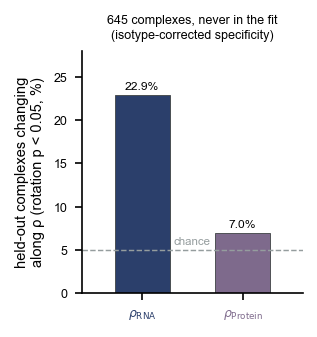

In [18]:
fig, ax = plt.subplots(figsize=(1.9, 2.1))
v = [100 * (cx[m].p < 0.05).mean() for m in modalities]
ax.bar(range(2), v, 0.55, color=[MODALITY[m] for m in modalities], edgecolor=INK, lw=0.4)
for i, vv in enumerate(v): ax.text(i, vv + 0.6, f"{vv:.1f}%", ha="center", fontsize=5.8)
ax.axhline(5, color=REFERENCE, lw=0.7, ls="--"); ax.text(0.5, 5.6, "chance", fontsize=5.5, color=REFERENCE, ha="center")
ax.set_xticks(range(2)); ax.set_xticklabels([RHO[m] for m in modalities])
for tl, m in zip(ax.get_xticklabels(), modalities): tl.set_color(MODALITY[m])
ax.set_ylabel("held-out complexes changing\nalong ρ (rotation p < 0.05, %)"); ax.set_ylim(0, 28); ax.set_xlim(-0.6, 1.6)
ax.set_title(f"{len(names_cx)} complexes, never in the fit\n(isotype-corrected specificity)", fontsize=6)
plt.show()

## Fig. 5f, g: specificity of held-out complexes in octiles of rho_RNA (f) and rho_Protein (g)
Log2 observed/expected minus isotype control, row-centred. Shown are the complexes with rotation p < 0.05 that change most steeply
at each end (12 per end for `rho_RNA`, 10 for `rho_Protein`). The 30-bin profiles are averaged into 8 groups. Row labels are coloured
by the end they rise toward.

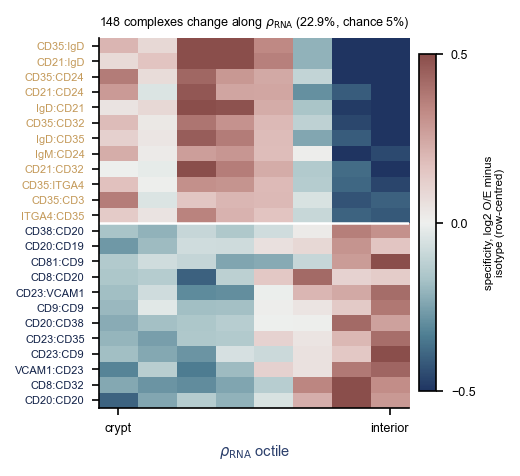

In [19]:
nice = lambda c: c.replace("CD279", "PD-1").replace("HLADPRQ", "MHC-II")

def heat(ax, m, n_end, ends, end_cols):
    sig = cx[m][cx[m].p < 0.05].sort_values("slope")
    rows = list(sig.index[:n_end]) + list(sig.index[::-1][:n_end][::-1])
    g = np.array_split(np.arange(N_PROF), 8)
    H = np.array([[profile[m][r].values[i].mean() for i in g] for r in rows]); H -= H.mean(1, keepdims=True)
    im = ax.imshow(H, cmap=CMAP["score"], vmin=-0.5, vmax=0.5, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([nice(r) for r in rows], fontsize=5.3)
    for tl, r in zip(ax.get_yticklabels(), rows): tl.set_color(end_cols[0] if cx[m].loc[r, "slope"] < 0 else end_cols[1])
    ax.axhline(n_end - 0.5, color="white", lw=1.2)
    ax.set_xticks([0, 7]); ax.set_xticklabels(ends); ax.set_xlabel(f"{RHO[m]} octile", color=MODALITY[m])
    ax.set_title(f"{len(sig)} complexes change along {RHO[m]} ({100 * (cx[m].p < 0.05).mean():.1f}%, chance 5%)", fontsize=6)
    cb = plt.colorbar(im, ax=ax, ticks=[-0.5, 0, 0.5], fraction=0.05, pad=0.03)
    cb.set_label("specificity, log2 O/E minus\nisotype (row-centred)", fontsize=5.5)

fig, ax = plt.subplots(figsize=(2.9, 3.2))
heat(ax, "RNA", 12, ["crypt", "interior"], (DOMCOL["crypt epithelium"], DOMCOL["germinal centre"]))
plt.show()

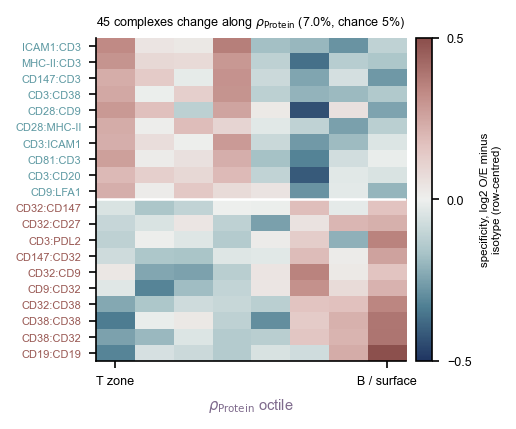

In [20]:
fig, ax = plt.subplots(figsize=(2.9, 2.8))
heat(ax, "Protein", 10, ["T zone", "B / surface"], (DOMCOL["T / Tfh-FDC"], DOMCOL["CD9+ CD38+ surface"]))
plt.show()

## Fig. 5h: example contact complexes
VLA-4-VCAM-1 and VCAM-1-CD23 along `rho_RNA`, MHC-II-CD3 and ICAM-1-CD3 along `rho_Protein`. Single spots hold few reads, so specificity is pooled in 30 equal-count bins;
each bin takes its majority domain and `fit_gauss` fits the bins per domain (F-test gate t = 0.1). The left map pools each spot with
its 6 nearest neighbours, for display. The p value is the rotation p of the 8-bin slope above.

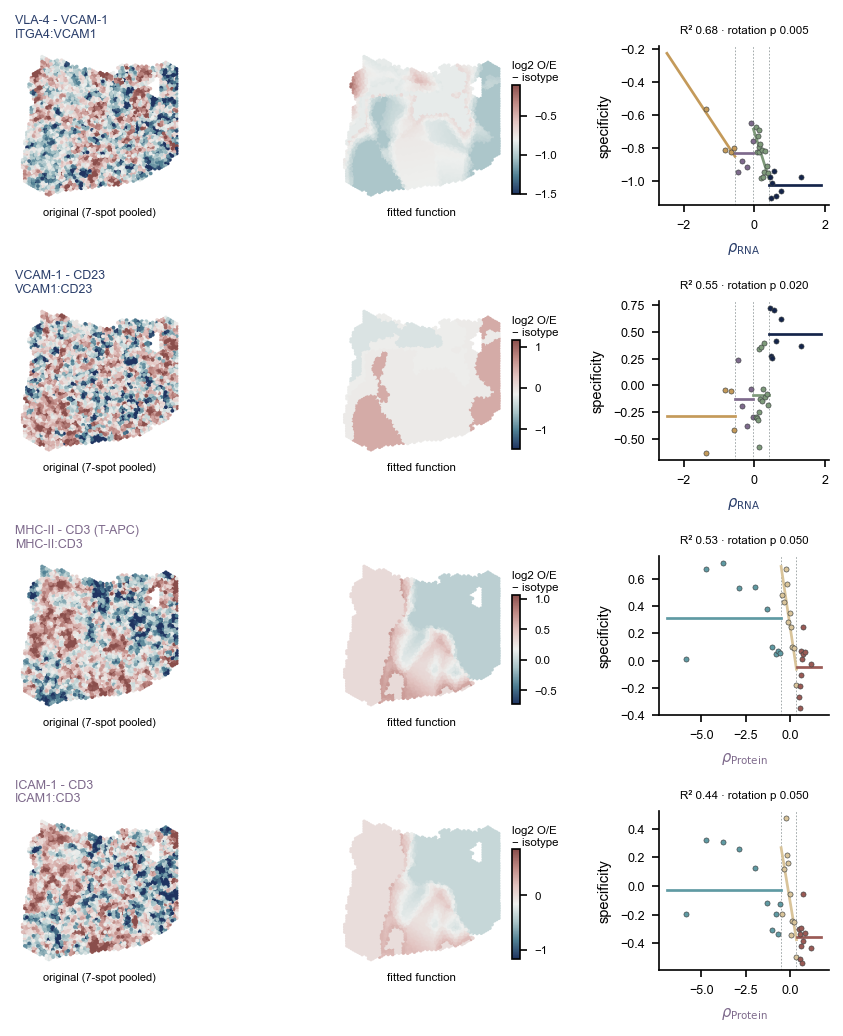

In [21]:
def contact_function(name, m, k=7, nb=N_PROF):
    j = names_cx.index(name); one = lambda H: specificity(H, O[:, [j]], E[:, [j]], ia[[j]], ib[[j]])[:, 0]
    dd, ll = d[m], lab[m]; n = len(dd)
    nn = cKDTree(coords).query(coords, k=k)[1]
    H_knn = sp.csr_matrix((np.ones(n * k), (nn.ravel(), np.repeat(np.arange(n), k))), shape=(n, n)).toarray()
    g = np.minimum((np.argsort(np.argsort(dd)) * nb) // n, nb - 1)
    by, bx = one(np.eye(nb)[g]), np.array([dd[g == i].mean() for i in range(nb)])
    bl = np.array([np.bincount(ll[g == i], minlength=ll.max() + 1).argmax() for i in range(nb)])
    sl, it = pw.fit_gauss(by[:, None], bl, bx, t=0.1); sl, it = sl[0], it[0]
    pred = it[bl] + sl[bl] * bx
    return dict(pooled=one(H_knn), fit=it[ll] + sl[ll] * dd, bx=bx, by=by, bl=bl, sl=sl, it=it,
                r2=1 - ((by - pred) ** 2).sum() / ((by - by.mean()) ** 2).sum())

CCC_EX = [("RNA", "ITGA4:VCAM1", "VLA-4 - VCAM-1"), ("RNA", "VCAM1:CD23", "VCAM-1 - CD23"),
          ("Protein", "HLADPRQ:CD3", "MHC-II - CD3 (T-APC)"), ("Protein", "ICAM1:CD3", "ICAM-1 - CD3")]
fig, ax = plt.subplots(len(CCC_EX), 3, figsize=(7.0, 2.0 * len(CCC_EX)), gridspec_kw=dict(wspace=0.9, hspace=0.6))
for r, (m, name, title) in enumerate(CCC_EX):
    F = contact_function(name, m); p = cx[m].loc[name, "p"]
    lo, hi = np.percentile(np.r_[F["pooled"], F["fit"]], [2, 98])
    saturn.plotting.spatial(ax[r, 0], coords, F["pooled"], "", cmap=CMAP["score"], vmin=lo, vmax=hi)
    s_ = saturn.plotting.spatial(ax[r, 1], coords, F["fit"], "", cmap=CMAP["score"], vmin=lo, vmax=hi)
    cbar(fig, ax[r, 1], s_, "log2 O/E\n− isotype")
    ax[r, 0].set_title(f"{title}\n{nice(name)}", color=MODALITY[m], loc="left", fontsize=6.0)
    ax[r, 0].text(0.5, -0.04, "original (7-spot pooled)", transform=ax[r, 0].transAxes, ha="center", va="top", fontsize=5.3)
    ax[r, 1].text(0.5, -0.04, "fitted function", transform=ax[r, 1].transAxes, ha="center", va="top", fontsize=5.5)
    along(ax[r, 2], m, F["bx"], F["by"], F["bl"], lambda k, xs, F=F: F["it"][k] + F["sl"][k] * xs, "specificity")
    ax[r, 2].set_title(f"R² {F['r2']:.2f} · rotation p {p:.3f}", fontsize=5.6)
plt.show()